Mounted at /content/drive
DATASET LOADED SUCCESSFULLY
Dataset shape: (171496, 16)
Number of charging sessions: 2649

First 5 rows:


,id,transaction_id,begin_time,end_time,total_charging_kwh,total_charging_min,current_soc,current_energy_meter_value,chargingv,charginga,out_power,charging_gun_temperature1,charging_gun_temperature2,types,class_judge,label
0,2329,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:44:53,0.03,0,45,352693.09,331.9,56.39,18.71,38,48,3,1,0
1,2344,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:45:53,0.55,1,46,352693.62,335.9,99.89,33.55,38,47,3,1,0
2,2358,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:46:53,1.08,2,46,352694.16,336.3,99.80,33.56,37,46,3,1,0
3,2372,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:47:53,1.69,3,47,352694.75,336.7,99.89,33.63,36,47,3,1,0
4,2385,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:48:53,2.21,4,48,352695.28,337.0,99.80,33.63,36,47,3,1,0



Session-level feature table:
Shape: (2649, 55)

Final feature table:
Shape: (2649, 58)


FEATURE / TARGET INFORMATION
Number of features: 57
Number of sessions: 2649

Class distribution:
label
0    2378
1     271
Name: count, dtype: int64

Training sessions: 2119
Testing sessions: 530

Scale positive weight: 8.765


STARTING XGBOOST TRAINING

XGBoost training completed!


XGBOOST FINAL RESULTS
Accuracy       : 0.9962
Precision      : 1.0000
Recall         : 0.9630
F1 Score       : 0.9811
ROC-AUC        : 0.9992
R² Score       : 0.9581

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       476
      Faulty       1.00      0.96      0.98        54

    accuracy                           1.00       530
   macro avg       1.00      0.98      0.99       530
weighted avg       1.00      1.00      1.00       530


Confusion Matrix:
[[476   0]
 [  2  52]]


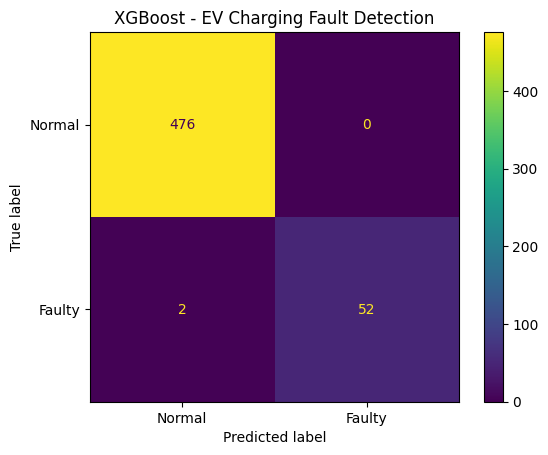


Top 15 XGBoost Features:


,Feature,Importance
0,energy_max,0.354859
1,voltage_min,0.195676
2,voltage_start,0.067274
3,energy_end,0.062677
4,energy_start,0.061003
5,power_max,0.043608
6,power_mean,0.014404
7,energy_per_soc,0.013300
8,soc_mean,0.011955
9,temp2_min,0.011392


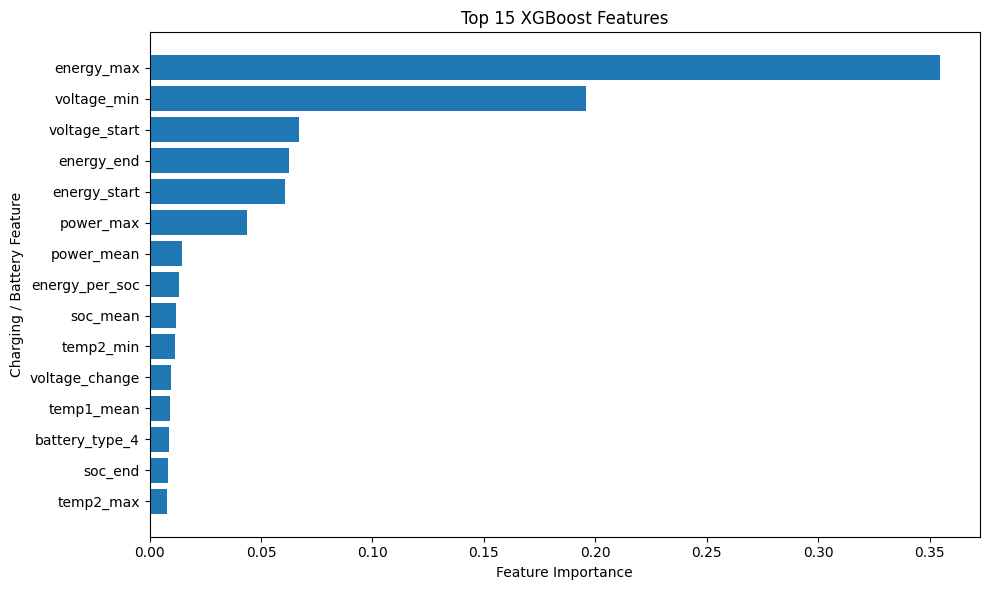



XGBOOST RESULTS TABLE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,R2 Score
0,XGBoost,0.996226,1.0,0.962963,0.981132,0.999222,0.958078




XGBOOST FILES SAVED SUCCESSFULLY
Results: /content/drive/MyDrive/Anomoly_dataset/xgboost_results.csv
Model: /content/drive/MyDrive/Anomoly_dataset/xgboost_model.pkl
Features: /content/drive/MyDrive/Anomoly_dataset/xgboost_feature_names.csv


In [2]:
# ============================================================
# SPARKEV MODULE 2
# MODEL 4: XGBOOST FOR EV CHARGING FAULT DETECTION
# ============================================================

# ============================================================
# 1. INSTALL / IMPORT LIBRARIES
# ============================================================

!pip -q install xgboost openpyxl

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    r2_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")


# ============================================================
# 3. LOAD DATASET
# ============================================================

DATA_PATH = (
    "/content/drive/MyDrive/"
    "Anomoly_dataset/"
    "processed_data_longer_than_30.xlsx"
)

df = pd.read_excel(DATA_PATH)

print("=" * 65)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 65)

print("Dataset shape:", df.shape)

print(
    "Number of charging sessions:",
    df["transaction_id"].nunique()
)

print("\nFirst 5 rows:")
display(df.head())


# ============================================================
# 4. PREPARE DATA
# ============================================================

df["begin_time"] = pd.to_datetime(
    df["begin_time"]
)

df["end_time"] = pd.to_datetime(
    df["end_time"]
)

df = df.sort_values(
    ["transaction_id", "end_time"]
).reset_index(drop=True)


# ============================================================
# 5. CREATE SESSION-LEVEL FEATURES
# ============================================================
# XGBoost will use the same type of session-level features
# used for your Isolation Forest experiment.
#
# This makes the comparison fair because both models analyse
# charging-session behaviour.

def first_value(x):
    return x.iloc[0]


def last_value(x):
    return x.iloc[-1]


session_features = (
    df.groupby("transaction_id")
    .agg(
        label=("label", "first"),

        battery_type=("types", "first"),

        # ---------------- SOC ----------------

        soc_start=("current_soc", first_value),
        soc_end=("current_soc", last_value),
        soc_min=("current_soc", "min"),
        soc_max=("current_soc", "max"),
        soc_mean=("current_soc", "mean"),
        soc_std=("current_soc", "std"),

        # ---------------- VOLTAGE ----------------

        voltage_start=("chargingv", first_value),
        voltage_end=("chargingv", last_value),
        voltage_min=("chargingv", "min"),
        voltage_max=("chargingv", "max"),
        voltage_mean=("chargingv", "mean"),
        voltage_std=("chargingv", "std"),

        # ---------------- CURRENT ----------------

        current_start=("charginga", first_value),
        current_end=("charginga", last_value),
        current_min=("charginga", "min"),
        current_max=("charginga", "max"),
        current_mean=("charginga", "mean"),
        current_std=("charginga", "std"),

        # ---------------- POWER ----------------

        power_start=("out_power", first_value),
        power_end=("out_power", last_value),
        power_min=("out_power", "min"),
        power_max=("out_power", "max"),
        power_mean=("out_power", "mean"),
        power_std=("out_power", "std"),

        # ---------------- TEMPERATURE 1 ----------------

        temp1_start=(
            "charging_gun_temperature1",
            first_value
        ),

        temp1_end=(
            "charging_gun_temperature1",
            last_value
        ),

        temp1_min=(
            "charging_gun_temperature1",
            "min"
        ),

        temp1_max=(
            "charging_gun_temperature1",
            "max"
        ),

        temp1_mean=(
            "charging_gun_temperature1",
            "mean"
        ),

        temp1_std=(
            "charging_gun_temperature1",
            "std"
        ),

        # ---------------- TEMPERATURE 2 ----------------

        temp2_start=(
            "charging_gun_temperature2",
            first_value
        ),

        temp2_end=(
            "charging_gun_temperature2",
            last_value
        ),

        temp2_min=(
            "charging_gun_temperature2",
            "min"
        ),

        temp2_max=(
            "charging_gun_temperature2",
            "max"
        ),

        temp2_mean=(
            "charging_gun_temperature2",
            "mean"
        ),

        temp2_std=(
            "charging_gun_temperature2",
            "std"
        ),

        # ---------------- ENERGY ----------------

        energy_start=(
            "current_energy_meter_value",
            first_value
        ),

        energy_end=(
            "current_energy_meter_value",
            last_value
        ),

        energy_max=(
            "current_energy_meter_value",
            "max"
        ),

        # ---------------- DURATION ----------------

        duration_max=(
            "total_charging_min",
            "max"
        ),

        # Number of observations in session

        num_points=(
            "transaction_id",
            "count"
        )
    )
)


# ============================================================
# 6. ADD DERIVED BEHAVIOURAL FEATURES
# ============================================================

session_features["soc_gain"] = (
    session_features["soc_end"]
    -
    session_features["soc_start"]
)

session_features["voltage_change"] = (
    session_features["voltage_end"]
    -
    session_features["voltage_start"]
)

session_features["current_change"] = (
    session_features["current_end"]
    -
    session_features["current_start"]
)

session_features["power_change"] = (
    session_features["power_end"]
    -
    session_features["power_start"]
)

session_features["temp1_rise"] = (
    session_features["temp1_end"]
    -
    session_features["temp1_start"]
)

session_features["temp2_rise"] = (
    session_features["temp2_end"]
    -
    session_features["temp2_start"]
)

session_features["temp_sensor_difference"] = (
    session_features["temp1_max"]
    -
    session_features["temp2_max"]
)

session_features["energy_delivered"] = (
    session_features["energy_end"]
    -
    session_features["energy_start"]
)


# ============================================================
# 7. ENERGY PER SOC GAIN
# ============================================================

session_features["energy_per_soc"] = np.where(
    session_features["soc_gain"] > 0,
    session_features["energy_delivered"]
    /
    session_features["soc_gain"],
    0
)


# ============================================================
# 8. SOC-RELATED BEHAVIOURAL FLAGS
# ============================================================

session_features["high_soc_start"] = (
    session_features["soc_start"] >= 80
).astype(int)

session_features["high_soc_session"] = (
    session_features["soc_max"] >= 90
).astype(int)

session_features["very_high_soc_session"] = (
    session_features["soc_max"] >= 95
).astype(int)


# ============================================================
# 9. HANDLE MISSING VALUES
# ============================================================

session_features = (
    session_features
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)


print("\nSession-level feature table:")
print(
    "Shape:",
    session_features.shape
)


# ============================================================
# 10. ONE-HOT ENCODE BATTERY TYPE
# ============================================================

session_features = pd.get_dummies(
    session_features,
    columns=["battery_type"],
    prefix="battery_type"
)


# Convert boolean columns to integers
for col in session_features.columns:

    if session_features[col].dtype == bool:

        session_features[col] = (
            session_features[col]
            .astype(int)
        )


print("\nFinal feature table:")
print(
    "Shape:",
    session_features.shape
)


# ============================================================
# 11. SEPARATE FEATURES AND TARGET
# ============================================================

X = session_features.drop(
    columns=["label"]
)

y = session_features["label"].astype(int)


print("\n")
print("=" * 65)
print("FEATURE / TARGET INFORMATION")
print("=" * 65)

print(
    "Number of features:",
    X.shape[1]
)

print(
    "Number of sessions:",
    X.shape[0]
)

print("\nClass distribution:")
print(y.value_counts())


# ============================================================
# 12. TRAIN / TEST SPLIT
# ============================================================
# Same 80/20 stratified approach.
#
# The test set is kept completely separate from training.

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


print("\nTraining sessions:", len(X_train))

print("Testing sessions:", len(X_test))


# ============================================================
# 13. CALCULATE CLASS IMBALANCE
# ============================================================

negative_count = (
    (y_train == 0).sum()
)

positive_count = (
    (y_train == 1).sum()
)

scale_pos_weight = (
    negative_count /
    positive_count
)

print(
    "\nScale positive weight:",
    round(scale_pos_weight, 3)
)


# ============================================================
# 14. BUILD XGBOOST MODEL
# ============================================================

xgb_model = XGBClassifier(

    n_estimators=300,

    max_depth=5,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    scale_pos_weight=scale_pos_weight,

    random_state=42,

    n_jobs=-1
)


# ============================================================
# 15. TRAIN XGBOOST
# ============================================================

print("\n")
print("=" * 65)
print("STARTING XGBOOST TRAINING")
print("=" * 65)

xgb_model.fit(
    X_train,
    y_train
)

print("\nXGBoost training completed!")


# ============================================================
# 16. PREDICT TEST DATA
# ============================================================

xgb_probability = (
    xgb_model
    .predict_proba(X_test)[:, 1]
)

xgb_prediction = (
    xgb_probability >= 0.5
).astype(int)


# ============================================================
# 17. CALCULATE METRICS
# ============================================================

xgb_accuracy = accuracy_score(
    y_test,
    xgb_prediction
)

xgb_precision = precision_score(
    y_test,
    xgb_prediction,
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_prediction,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_prediction,
    zero_division=0
)

xgb_roc_auc = roc_auc_score(
    y_test,
    xgb_probability
)

# R² included for project comparison.
xgb_r2 = r2_score(
    y_test,
    xgb_probability
)


# ============================================================
# 18. DISPLAY FINAL RESULTS
# ============================================================

print("\n")
print("=" * 65)
print("XGBOOST FINAL RESULTS")
print("=" * 65)

print(
    f"Accuracy       : {xgb_accuracy:.4f}"
)

print(
    f"Precision      : {xgb_precision:.4f}"
)

print(
    f"Recall         : {xgb_recall:.4f}"
)

print(
    f"F1 Score       : {xgb_f1:.4f}"
)

print(
    f"ROC-AUC        : {xgb_roc_auc:.4f}"
)

print(
    f"R² Score       : {xgb_r2:.4f}"
)

print("=" * 65)


# ============================================================
# 19. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        xgb_prediction,
        target_names=[
            "Normal",
            "Faulty"
        ],
        zero_division=0
    )
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

cm_xgb = confusion_matrix(
    y_test,
    xgb_prediction
)

print("\nConfusion Matrix:")

print(cm_xgb)


# ============================================================
# 21. CONFUSION MATRIX VISUALIZATION
# ============================================================

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=[
        "Normal",
        "Faulty"
    ]
).plot()

plt.title(
    "XGBoost - EV Charging Fault Detection"
)

plt.show()


# ============================================================
# 22. FEATURE IMPORTANCE
# ============================================================
# This is particularly useful for your project presentation.
#
# It tells us which charging/battery features contributed most
# to the XGBoost predictions.

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": (
        xgb_model
        .feature_importances_
    )

})

importance = (
    importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nTop 15 XGBoost Features:")

display(
    importance.head(15)
)


# ============================================================
# 23. PLOT TOP 15 FEATURE IMPORTANCES
# ============================================================

top_features = importance.head(15)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Charging / Battery Feature"
)

plt.title(
    "Top 15 XGBoost Features"
)

plt.tight_layout()

plt.show()


# ============================================================
# 24. CREATE RESULTS TABLE
# ============================================================

xgb_results = pd.DataFrame({

    "Model": [
        "XGBoost"
    ],

    "Accuracy": [
        xgb_accuracy
    ],

    "Precision": [
        xgb_precision
    ],

    "Recall": [
        xgb_recall
    ],

    "F1 Score": [
        xgb_f1
    ],

    "ROC-AUC": [
        xgb_roc_auc
    ],

    "R2 Score": [
        xgb_r2
    ]

})


print("\n")
print("=" * 65)
print("XGBOOST RESULTS TABLE")
print("=" * 65)

display(
    xgb_results
)


# ============================================================
# 25. SAVE RESULTS
# ============================================================

RESULTS_PATH = (
    "/content/drive/MyDrive/"
    "Anomoly_dataset/"
    "xgboost_results.csv"
)

MODEL_PATH = (
    "/content/drive/MyDrive/"
    "Anomoly_dataset/"
    "model2_charging_fault_xgb.pkl"
)

FEATURE_PATH = (
    "/content/drive/MyDrive/"
    "Anomoly_dataset/"
    "xgboost_feature_names.csv"
)


xgb_results.to_csv(
    RESULTS_PATH,
    index=False
)


joblib.dump(
    xgb_model,
    MODEL_PATH
)


pd.DataFrame({
    "feature_name": X.columns
}).to_csv(
    FEATURE_PATH,
    index=False
)


print("\n")
print("=" * 65)
print("XGBOOST FILES SAVED SUCCESSFULLY")
print("=" * 65)

print(
    "Results:",
    RESULTS_PATH
)

print(
    "Model:",
    MODEL_PATH
)

print(
    "Features:",
    FEATURE_PATH
)

print("=" * 65)

XGBOOST SANITY CHECK
Testing model without energy-related features

Energy-related features being removed:
- energy_start
- energy_end
- energy_max
- energy_delivered
- energy_per_soc

Features found in X:
- energy_start
- energy_end
- energy_max
- energy_delivered
- energy_per_soc


FEATURE COMPARISON
Original number of features: 57
Reduced number of features: 52
Features removed: 5

Training sessions: 2119
Testing sessions: 530

Scale positive weight: 8.765


TRAINING SANITY-CHECK XGBOOST

Training completed!


XGBOOST SANITY-CHECK RESULTS
Accuracy       : 0.9962
Precision      : 1.0000
Recall         : 0.9630
F1 Score       : 0.9811
ROC-AUC        : 0.9998
R² Score       : 0.9693

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       476
      Faulty       1.00      0.96      0.98        54

    accuracy                           1.00       530
   macro avg       1.00      0.98      0.99       530
weighted avg

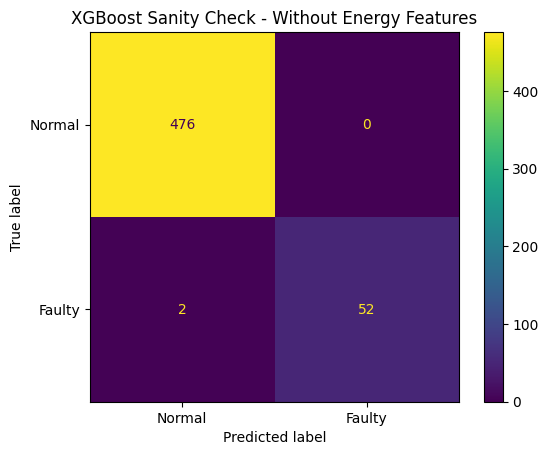


Top 15 Features After Removing Energy Features:


,Feature,Importance
0,voltage_min,0.257091
1,high_soc_session,0.114154
2,voltage_start,0.063336
3,temp2_std,0.056994
4,soc_max,0.047041
5,power_max,0.040322
6,temp2_end,0.030033
7,temp_sensor_difference,0.024104
8,battery_type_4,0.022460
9,power_mean,0.018893




ORIGINAL VS SANITY-CHECK COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,R2 Score
0,Original XGBoost,0.9962,1.0,0.963,0.9811,0.9992,0.9581
1,XGBoost without Energy Features,0.9962,1.0,0.963,0.9811,0.9998,0.9693




PERFORMANCE DIFFERENCE
Accuracy difference : 0.0000
F1 difference       : 0.0000
ROC-AUC difference  : -0.0006

Sanity-check results saved to:
/content/drive/MyDrive/Anomoly_dataset/xgboost_sanity_check_results.csv


In [3]:
# ============================================================
# XGBOOST SANITY CHECK
# REMOVE ENERGY-RELATED FEATURES
# ============================================================

print("=" * 70)
print("XGBOOST SANITY CHECK")
print("Testing model without energy-related features")
print("=" * 70)


# ============================================================
# 1. IDENTIFY ENERGY-RELATED FEATURES
# ============================================================

energy_features = [
    "energy_start",
    "energy_end",
    "energy_max",
    "energy_delivered",
    "energy_per_soc"
]

print("\nEnergy-related features being removed:")

for feature in energy_features:
    print("-", feature)


# ============================================================
# 2. CHECK WHICH FEATURES ACTUALLY EXIST
# ============================================================

energy_features_present = [
    feature
    for feature in energy_features
    if feature in X.columns
]

print("\nFeatures found in X:")

for feature in energy_features_present:
    print("-", feature)


# ============================================================
# 3. CREATE REDUCED FEATURE SET
# ============================================================

X_sanity = X.drop(
    columns=energy_features_present
).copy()


print("\n")
print("=" * 70)
print("FEATURE COMPARISON")
print("=" * 70)

print(
    "Original number of features:",
    X.shape[1]
)

print(
    "Reduced number of features:",
    X_sanity.shape[1]
)

print(
    "Features removed:",
    len(energy_features_present)
)


# ============================================================
# 4. SAME TRAIN / TEST SPLIT
# ============================================================
# IMPORTANT:
# Use exactly the same random_state and stratification
# so that the comparison is fair.

X_train_sanity, X_test_sanity, y_train_sanity, y_test_sanity = (
    train_test_split(
        X_sanity,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)


print("\nTraining sessions:",
      len(X_train_sanity))

print("Testing sessions:",
      len(X_test_sanity))


# ============================================================
# 5. HANDLE CLASS IMBALANCE
# ============================================================

negative_count_sanity = (
    (y_train_sanity == 0).sum()
)

positive_count_sanity = (
    (y_train_sanity == 1).sum()
)

scale_pos_weight_sanity = (
    negative_count_sanity /
    positive_count_sanity
)

print(
    "\nScale positive weight:",
    round(scale_pos_weight_sanity, 3)
)


# ============================================================
# 6. CREATE SANITY-CHECK XGBOOST MODEL
# ============================================================

xgb_sanity_model = XGBClassifier(

    n_estimators=300,

    max_depth=5,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    scale_pos_weight=scale_pos_weight_sanity,

    random_state=42,

    n_jobs=-1
)


# ============================================================
# 7. TRAIN SANITY-CHECK MODEL
# ============================================================

print("\n")
print("=" * 70)
print("TRAINING SANITY-CHECK XGBOOST")
print("=" * 70)

xgb_sanity_model.fit(
    X_train_sanity,
    y_train_sanity
)

print("\nTraining completed!")


# ============================================================
# 8. PREDICT
# ============================================================

sanity_probability = (
    xgb_sanity_model
    .predict_proba(
        X_test_sanity
    )[:, 1]
)

sanity_prediction = (
    sanity_probability >= 0.5
).astype(int)


# ============================================================
# 9. CALCULATE METRICS
# ============================================================

sanity_accuracy = accuracy_score(
    y_test_sanity,
    sanity_prediction
)

sanity_precision = precision_score(
    y_test_sanity,
    sanity_prediction,
    zero_division=0
)

sanity_recall = recall_score(
    y_test_sanity,
    sanity_prediction,
    zero_division=0
)

sanity_f1 = f1_score(
    y_test_sanity,
    sanity_prediction,
    zero_division=0
)

sanity_roc_auc = roc_auc_score(
    y_test_sanity,
    sanity_probability
)

sanity_r2 = r2_score(
    y_test_sanity,
    sanity_probability
)


# ============================================================
# 10. DISPLAY SANITY-CHECK RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("XGBOOST SANITY-CHECK RESULTS")
print("=" * 70)

print(
    f"Accuracy       : {sanity_accuracy:.4f}"
)

print(
    f"Precision      : {sanity_precision:.4f}"
)

print(
    f"Recall         : {sanity_recall:.4f}"
)

print(
    f"F1 Score       : {sanity_f1:.4f}"
)

print(
    f"ROC-AUC        : {sanity_roc_auc:.4f}"
)

print(
    f"R² Score       : {sanity_r2:.4f}"
)

print("=" * 70)


# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        y_test_sanity,
        sanity_prediction,
        target_names=[
            "Normal",
            "Faulty"
        ],
        zero_division=0
    )
)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm_sanity = confusion_matrix(
    y_test_sanity,
    sanity_prediction
)

print("\nConfusion Matrix:")

print(cm_sanity)


# ============================================================
# 13. CONFUSION MATRIX PLOT
# ============================================================

ConfusionMatrixDisplay(
    confusion_matrix=cm_sanity,
    display_labels=[
        "Normal",
        "Faulty"
    ]
).plot()

plt.title(
    "XGBoost Sanity Check - Without Energy Features"
)

plt.show()


# ============================================================
# 14. FEATURE IMPORTANCE
# ============================================================

sanity_importance = pd.DataFrame({

    "Feature":
        X_sanity.columns,

    "Importance":
        xgb_sanity_model.feature_importances_

})

sanity_importance = (
    sanity_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nTop 15 Features After Removing Energy Features:")

display(
    sanity_importance.head(15)
)


# ============================================================
# 15. COMPARE ORIGINAL VS SANITY CHECK
# ============================================================

comparison = pd.DataFrame({

    "Model": [
        "Original XGBoost",
        "XGBoost without Energy Features"
    ],

    "Accuracy": [
        xgb_accuracy,
        sanity_accuracy
    ],

    "Precision": [
        xgb_precision,
        sanity_precision
    ],

    "Recall": [
        xgb_recall,
        sanity_recall
    ],

    "F1 Score": [
        xgb_f1,
        sanity_f1
    ],

    "ROC-AUC": [
        xgb_roc_auc,
        sanity_roc_auc
    ],

    "R2 Score": [
        xgb_r2,
        sanity_r2
    ]
})


print("\n")
print("=" * 70)
print("ORIGINAL VS SANITY-CHECK COMPARISON")
print("=" * 70)

display(
    comparison.round(4)
)


# ============================================================
# 16. CALCULATE PERFORMANCE DROP
# ============================================================

accuracy_drop = (
    xgb_accuracy -
    sanity_accuracy
)

roc_auc_drop = (
    xgb_roc_auc -
    sanity_roc_auc
)

f1_drop = (
    xgb_f1 -
    sanity_f1
)


print("\n")
print("=" * 70)
print("PERFORMANCE DIFFERENCE")
print("=" * 70)

print(
    f"Accuracy difference : {accuracy_drop:.4f}"
)

print(
    f"F1 difference       : {f1_drop:.4f}"
)

print(
    f"ROC-AUC difference  : {roc_auc_drop:.4f}"
)

print("=" * 70)


# ============================================================
# 17. SAVE SANITY-CHECK RESULTS
# ============================================================

sanity_results_path = (
    "/content/drive/MyDrive/"
    "Anomoly_dataset/"
    "xgboost_sanity_check_results.csv"
)

comparison.to_csv(
    sanity_results_path,
    index=False
)


print(
    "\nSanity-check results saved to:"
)

print(
    sanity_results_path
)